# Theme Alpha Q3: Structure Robustness

Q1 found LowVolTrend RiskParity as a promising strong-theme factor. Q2 showed the factor does not look like a single magic parameter.

Q3 tests structural robustness:

1. Should gold be filtered like equity themes, always eligible, or held with a floor?
2. Does LowVolTrend survive if Nasdaq or Chip is removed?
3. Does an expanded theme pool improve robustness or dilute the factor?


In [ ]:
# Keep relative research paths stable after this notebook moved.
import os
from xquant.project import find_repo_root

REPO_ROOT = find_repo_root()
os.chdir(REPO_ROOT)


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

warnings.filterwarnings("ignore")
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "SimHei", "STHeiti"]
plt.rcParams["axes.unicode_minus"] = False

OUTPUT_DIR = Path("outputs/theme-alpha-q3-structure-robustness")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_START = "2023-01-01"
END = (pd.Timestamp.today() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
TRADING_DAYS = 252
INITIAL_NAV = 100.0
REBALANCE_DAYS = 10
REBALANCE_ANCHOR = "2024-01-02"

CSI300 = "510300.SS"
NASDAQ = "513100.SS"
NONFERROUS = "512400.SS"
CHIP = "159995.SZ"
COMM = "515880.SS"
GOLD = "518880.SS"
DIVIDEND = "510880.SS"
ENERGY = "159930.SZ"
BROKER = "512880.SS"
HK_TECH = "513180.SS"
HEALTHCARE = "512170.SS"

BASELINE_ASSETS = (CSI300, NASDAQ, GOLD)
ORIGINAL_THEME = (NASDAQ, NONFERROUS, CHIP, COMM, GOLD)
EXTENDED_THEME = (NASDAQ, NONFERROUS, CHIP, COMM, GOLD, DIVIDEND, ENERGY, BROKER, HK_TECH, HEALTHCARE)
ALL_SYMBOLS = tuple(dict.fromkeys(BASELINE_ASSETS + EXTENDED_THEME))

SYMBOL_NAMES = {
    CSI300: "沪深300ETF",
    NASDAQ: "纳指100ETF",
    NONFERROUS: "有色金属ETF",
    CHIP: "芯片ETF",
    COMM: "通信ETF",
    GOLD: "黄金ETF",
    DIVIDEND: "红利ETF",
    ENERGY: "能源ETF",
    BROKER: "证券ETF",
    HK_TECH: "恒生科技ETF",
    HEALTHCARE: "医疗ETF",
}

MA_WINDOW = 60
MOM_WINDOW = 63
VOL_WINDOW = 60
TOP_N = 3
RP_VOL_WINDOW = 20
CAP = 0.50

WINDOWS = {
    "2025_only": ("2025-01-01", "2025-12-31"),
    "2026_ytd": ("2026-01-01", None),
    "2025_to_date": ("2025-01-01", None),
}

print(f"Output dir: {OUTPUT_DIR}")


Output dir: outputs/theme-alpha-q3-structure-robustness


## 1. Data Loading


In [2]:
def flatten_yfinance(df):
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    return df


def download_ohlc(symbol):
    df = yf.download(symbol, start=DATA_START, end=END, progress=False, auto_adjust=False, threads=False)
    df = flatten_yfinance(df)
    if df.empty:
        raise ValueError(f"No data for {symbol}")
    keep = [c for c in ["Open", "High", "Low", "Close", "Adj Close", "Volume"] if c in df.columns]
    df = df[keep].copy()
    df.columns = [c.lower().replace(" ", "_") for c in df.columns]
    df.index = pd.to_datetime(df.index).tz_localize(None)
    return df.sort_index()

market = {sym: download_ohlc(sym) for sym in ALL_SYMBOLS}
availability = pd.DataFrame([
    {"symbol": sym, "name": SYMBOL_NAMES[sym], "first_date": market[sym].index.min().date(), "last_date": market[sym].index.max().date(), "rows": len(market[sym])}
    for sym in ALL_SYMBOLS
])
availability.to_csv(OUTPUT_DIR / "data_availability.csv", index=False, encoding="utf-8-sig")
display(availability)

idx = None
for sym in ALL_SYMBOLS:
    cur = market[sym]["close"].dropna().index
    idx = cur if idx is None else idx.union(cur)
idx = pd.DatetimeIndex(idx).sort_values()
close = pd.DataFrame({sym: market[sym]["close"].reindex(idx) for sym in ALL_SYMBOLS}).ffill().dropna()
high = pd.DataFrame({sym: market[sym]["high"].reindex(close.index) for sym in ALL_SYMBOLS}).ffill()
low = pd.DataFrame({sym: market[sym]["low"].reindex(close.index) for sym in ALL_SYMBOLS}).ffill()
returns = close.pct_change().fillna(0.0)
print(f"Aligned sample: {close.index.min().date()} to {close.index.max().date()}, rows={len(close)}")


,symbol,name,first_date,last_date,rows
0,510300.SS,沪深300ETF,2023-01-03,2026-06-23,837
1,513100.SS,纳指100ETF,2023-01-03,2026-06-23,838
2,518880.SS,黄金ETF,2023-01-03,2026-06-23,837
3,512400.SS,有色金属ETF,2023-01-03,2026-06-23,837
4,159995.SZ,芯片ETF,2023-01-03,2026-06-23,837
5,515880.SS,通信ETF,2023-01-03,2026-06-23,837
6,510880.SS,红利ETF,2023-01-03,2026-06-23,837
7,159930.SZ,能源ETF,2023-01-03,2026-06-23,818
8,512880.SS,证券ETF,2023-01-03,2026-06-23,837
9,513180.SS,恒生科技ETF,2023-01-03,2026-06-23,837


Aligned sample: 2023-01-03 to 2026-06-23, rows=838


## 2. Helpers


In [3]:
def normalize_weights(weights, universe):
    clean = {sym: float(max(0.0, weights.get(sym, 0.0))) for sym in universe}
    total = sum(clean.values())
    if total > 1.0 + 1e-12:
        clean = {sym: val / total for sym, val in clean.items()}
        total = 1.0
    clean["CASH"] = max(0.0, 1.0 - total)
    return clean


def apply_cap(weights, universe, cap=None):
    if cap is None:
        return normalize_weights(weights, universe)
    s = pd.Series({sym: max(0.0, weights.get(sym, 0.0)) for sym in universe}, dtype=float)
    total = s.sum()
    if total <= 0:
        return normalize_weights({}, universe)
    s = s / total
    cap = float(cap)
    for _ in range(30):
        over = s > cap + 1e-12
        if not over.any():
            break
        excess = (s[over] - cap).sum()
        s[over] = cap
        under = s < cap - 1e-12
        capacity = (cap - s[under]).clip(lower=0.0)
        if excess <= 1e-12 or capacity.sum() <= 1e-12:
            break
        base = s[under].clip(lower=0.0)
        add = excess * (base / base.sum() if base.sum() > 1e-12 else capacity / capacity.sum())
        add = np.minimum(add, capacity)
        s.loc[add.index] += add
    return normalize_weights(s.to_dict(), universe)


def enforce_floor(weights, universe, floors):
    if not floors:
        return normalize_weights(weights, universe)
    base = normalize_weights(weights, universe)
    asset = pd.Series({sym: base.get(sym, 0.0) for sym in universe}, dtype=float)
    cash = base.get("CASH", 0.0)
    floor_series = pd.Series({sym: floors.get(sym, 0.0) for sym in universe}, dtype=float)
    floor_total = floor_series.sum()
    if floor_total >= 1.0:
        return normalize_weights(floor_series.to_dict(), universe)
    for sym, floor in floor_series[floor_series > 0].items():
        asset[sym] = max(asset.get(sym, 0.0), floor)
    excess_total = asset.sum()
    if excess_total > 1.0:
        floor_locked = floor_series[floor_series > 0]
        flexible = asset.index.difference(floor_locked.index)
        flexible_sum = asset.loc[flexible].sum()
        available = 1.0 - floor_locked.sum()
        if flexible_sum > 1e-12 and available > 0:
            asset.loc[flexible] = asset.loc[flexible] / flexible_sum * available
        elif available <= 0:
            asset.loc[flexible] = 0.0
        for sym, floor in floor_locked.items():
            asset[sym] = floor
        cash = 0.0
    else:
        cash = max(0.0, 1.0 - asset.sum())
    out = asset.to_dict()
    out["CASH"] = cash
    return out


def rebalance_dates(index):
    idx = pd.DatetimeIndex(index)
    start = idx.searchsorted(pd.Timestamp(REBALANCE_ANCHOR))
    return set(pd.DatetimeIndex(idx[start::REBALANCE_DAYS]))


def risk_parity_weight(date, eligible, universe, cap=None, floors=None):
    eligible = [sym for sym in eligible if sym in universe]
    floor_symbols = [sym for sym, val in (floors or {}).items() if val > 0 and sym in universe]
    eligible = list(dict.fromkeys(eligible + floor_symbols))
    if not eligible:
        return enforce_floor(normalize_weights({}, universe), universe, floors or {})
    loc = close.index.get_loc(date)
    if loc < RP_VOL_WINDOW:
        return enforce_floor(normalize_weights({}, universe), universe, floors or {})
    hist = returns.iloc[loc - RP_VOL_WINDOW + 1: loc + 1][eligible]
    vols = hist.std(ddof=1).replace(0, np.nan).dropna()
    vols = vols[vols > 0]
    if vols.empty:
        return enforce_floor(normalize_weights({}, universe), universe, floors or {})
    inv = 1.0 / vols
    raw = (inv / inv.sum()).to_dict()
    capped = apply_cap(raw, universe, cap)
    return enforce_floor(capped, universe, floors or {})


def equal_weight(eligible, universe):
    eligible = [sym for sym in eligible if sym in universe]
    if not eligible:
        return normalize_weights({}, universe)
    return normalize_weights({sym: 1.0 / len(eligible) for sym in eligible}, universe)


def low_vol_trend_selector(universe, always_include=()):
    always_include = tuple(sym for sym in always_include if sym in universe)
    def select(date):
        loc = close.index.get_loc(date)
        warmup = max(MA_WINDOW, MOM_WINDOW, VOL_WINDOW)
        if loc < warmup:
            return list(always_include)
        symbols = list(universe)
        normal_symbols = [sym for sym in symbols if sym not in always_include]
        price = close.iloc[loc][normal_symbols]
        ma = close.iloc[loc - MA_WINDOW + 1: loc + 1][normal_symbols].mean()
        mom = price / close.iloc[loc - MOM_WINDOW][normal_symbols] - 1.0
        vols = returns.iloc[loc - VOL_WINDOW + 1: loc + 1][normal_symbols].std(ddof=1)
        eligible = price.index[(price > ma) & (mom > 0)].tolist()
        slots = max(0, TOP_N - len(always_include))
        selected = list(always_include) + vols[eligible].sort_values().head(slots).index.tolist()
        return list(dict.fromkeys(selected))
    return select


def all_assets(universe):
    return lambda _date: list(universe)


def build_weights(universe, selector, allocator):
    rdates = rebalance_dates(close.index)
    rows = []
    last = normalize_weights({}, universe)
    for date in close.index:
        if date in rdates:
            last = allocator(date, selector(date))
        rows.append(last)
    out = pd.DataFrame(rows, index=close.index).fillna(0.0)
    for col in list(universe) + ["CASH"]:
        if col not in out.columns:
            out[col] = 0.0
    return out[list(universe) + ["CASH"]]


def turnover_from_signal_weights(signal_weights, universe):
    actual = signal_weights[list(universe) + ["CASH"]].shift(1).fillna(0.0)
    return 0.5 * actual.diff().abs().sum(axis=1).fillna(actual.abs().sum(axis=1))


def backtest_from_weights(name, universe, signal_weights, cost_bps=0.0):
    asset_weights = signal_weights[list(universe)].shift(1).fillna(0.0)
    gross = (asset_weights * returns[list(universe)]).sum(axis=1)
    turnover = turnover_from_signal_weights(signal_weights, universe)
    net = gross - turnover * (cost_bps / 10000.0)
    nav = (1.0 + net).cumprod() * INITIAL_NAV
    return {"name": name, "universe": tuple(universe), "weights": signal_weights, "returns": net, "gross_returns": gross, "turnover": turnover, "nav": nav.rename(name)}


def run_strategy(name, universe, selector, allocator, cost_bps=0.0):
    w = build_weights(universe, selector, allocator)
    return backtest_from_weights(name, universe, w, cost_bps)


def static_mix(name, weights_map, cost_bps=0.0):
    universe = tuple(weights_map.keys())
    total = sum(weights_map.values())
    w = pd.DataFrame(0.0, index=close.index, columns=list(universe) + ["CASH"])
    for sym, val in weights_map.items():
        w[sym] = val / total
    return backtest_from_weights(name, universe, w, cost_bps)


def nav_from_returns(r):
    return (1.0 + r).cumprod() * INITIAL_NAV


def metrics_row(name, r, weights=None, turnover=None):
    r = r.dropna()
    if len(r) == 0:
        return {"策略": name}
    nav = nav_from_returns(r)
    total = nav.iloc[-1] / INITIAL_NAV - 1.0
    ann = (1.0 + total) ** (TRADING_DAYS / len(r)) - 1.0
    vol = r.std(ddof=1) * np.sqrt(TRADING_DAYS) if len(r) > 1 else np.nan
    dd = nav / nav.cummax() - 1.0
    mdd = dd.min()
    sharpe = ann / vol if pd.notna(vol) and vol > 0 else np.nan
    calmar = ann / abs(mdd) if pd.notna(mdd) and mdd < 0 else np.nan
    monthly = r.resample("ME").apply(lambda x: (1.0 + x).prod() - 1.0)
    row = {"策略": name, "累计收益": total, "年化收益": ann, "年化波动": vol, "最大回撤": mdd, "夏普": sharpe, "卡玛": calmar, "月胜率": (monthly > 0).mean() if len(monthly) else np.nan, "最好月份": monthly.max() if len(monthly) else np.nan, "最差月份": monthly.min() if len(monthly) else np.nan}
    if turnover is not None:
        t = turnover.reindex(r.index).fillna(0.0)
        row["年化换手"] = t.mean() * TRADING_DAYS
    if weights is not None:
        w = weights.reindex(r.index).ffill().fillna(0.0)
        asset_cols = [c for c in w.columns if c != "CASH"]
        row["平均现金"] = w["CASH"].mean() if "CASH" in w else 0.0
        row["当前现金"] = w["CASH"].iloc[-1] if "CASH" in w else 0.0
        row["平均最大单资产权重"] = w[asset_cols].max(axis=1).mean() if asset_cols else np.nan
        row["当前最大单资产权重"] = w[asset_cols].iloc[-1].max() if asset_cols else np.nan
    return row


def slice_returns(port, start, end=None):
    r = port["returns"].loc[pd.Timestamp(start):]
    if end is not None:
        r = r.loc[:pd.Timestamp(end)]
    return r.dropna()


## 3. Strategy Variants


In [4]:
UNIVERSES = {
    "original": ORIGINAL_THEME,
    "no_nasdaq": tuple(sym for sym in ORIGINAL_THEME if sym != NASDAQ),
    "no_chip": tuple(sym for sym in ORIGINAL_THEME if sym != CHIP),
    "no_nasdaq_chip": tuple(sym for sym in ORIGINAL_THEME if sym not in (NASDAQ, CHIP)),
    "expanded": EXTENDED_THEME,
}


def lvt_strategy(name, universe, gold_mode="filtered", gold_floor=0.0, cost_bps=0.0):
    always = (GOLD,) if gold_mode in ("always", "floor") and GOLD in universe else tuple()
    floors = {GOLD: gold_floor} if gold_floor > 0 and GOLD in universe else {}
    return run_strategy(
        name,
        universe,
        low_vol_trend_selector(universe, always_include=always),
        lambda date, eligible, universe=universe, floors=floors: risk_parity_weight(date, eligible, universe, cap=CAP, floors=floors),
        cost_bps=cost_bps,
    )


def rp_strategy(name, universe, cost_bps=0.0):
    return run_strategy(name, universe, all_assets(universe), lambda date, eligible, universe=universe: risk_parity_weight(date, eligible, universe, cap=None), cost_bps=cost_bps)


def build_portfolios(cost_bps=0.0):
    ports = {
        "原三资产RiskParity": rp_strategy("原三资产RiskParity", BASELINE_ASSETS, cost_bps),
        "60_40沪深300黄金": static_mix("60_40沪深300黄金", {CSI300: 0.6, GOLD: 0.4}, cost_bps),
        "纯纳指ETF": static_mix("纯纳指ETF", {NASDAQ: 1.0}, cost_bps),
        "纯黄金ETF": static_mix("纯黄金ETF", {GOLD: 1.0}, cost_bps),
    }
    for uname, universe in UNIVERSES.items():
        ports[f"RP_{uname}"] = rp_strategy(f"RP_{uname}", universe, cost_bps)
        ports[f"LVT_{uname}_gold_filtered"] = lvt_strategy(f"LVT_{uname}_gold_filtered", universe, "filtered", 0.0, cost_bps)
        if GOLD in universe:
            ports[f"LVT_{uname}_gold_always"] = lvt_strategy(f"LVT_{uname}_gold_always", universe, "always", 0.0, cost_bps)
            ports[f"LVT_{uname}_gold_floor10"] = lvt_strategy(f"LVT_{uname}_gold_floor10", universe, "floor", 0.10, cost_bps)
            ports[f"LVT_{uname}_gold_floor15"] = lvt_strategy(f"LVT_{uname}_gold_floor15", universe, "floor", 0.15, cost_bps)
    return ports

portfolios = build_portfolios(cost_bps=0.0)
print(f"Portfolio count: {len(portfolios)}")
print("Key variants:")
for name in portfolios:
    if name.startswith("LVT_original") or name in ["RP_original", "原三资产RiskParity"]:
        print(" -", name)


Portfolio count: 29
Key variants:
 - 原三资产RiskParity
 - RP_original
 - LVT_original_gold_filtered
 - LVT_original_gold_always
 - LVT_original_gold_floor10
 - LVT_original_gold_floor15


## 4. Evaluation Tables


In [5]:
def evaluate(portfolios, window_name, start, end=None):
    rows = []
    navs = {}
    monthly = {}
    underwater = {}
    for name, port in portfolios.items():
        r = slice_returns(port, start, end)
        if len(r) < 20:
            continue
        rows.append(metrics_row(name, r, port["weights"], port["turnover"]))
        nav = nav_from_returns(r)
        navs[name] = nav
        monthly[name] = r.resample("ME").apply(lambda x: (1.0 + x).prod() - 1.0)
        underwater[name] = nav / nav.cummax() - 1.0
    summary = pd.DataFrame(rows).set_index("策略").sort_values("夏普", ascending=False)
    summary.to_csv(OUTPUT_DIR / f"summary_{window_name}.csv", encoding="utf-8-sig")
    pd.DataFrame(monthly).to_csv(OUTPUT_DIR / f"monthly_returns_{window_name}.csv", encoding="utf-8-sig")
    pd.DataFrame(underwater).to_csv(OUTPUT_DIR / f"underwater_{window_name}.csv", encoding="utf-8-sig")
    return summary, pd.DataFrame(navs)

summary_tables = {}
nav_tables = {}
for window_name, (start, end) in WINDOWS.items():
    summary, navs = evaluate(portfolios, window_name, start, end)
    summary_tables[window_name] = summary
    nav_tables[window_name] = navs
    print()
    print(f"Summary - {window_name}")
    display(summary[["累计收益", "年化收益", "最大回撤", "夏普", "卡玛", "年化换手", "平均现金", "平均最大单资产权重"]].round(4).head(30))

latest_rows = []
avg_rows = []
for name, port in portfolios.items():
    w = port["weights"].loc["2025-01-01":]
    asset_cols = [c for c in w.columns if c != "CASH"]
    latest_rows.append({"策略": name, **{SYMBOL_NAMES.get(c, c): w[c].iloc[-1] for c in asset_cols}, "现金": w["CASH"].iloc[-1]})
    avg_rows.append({"策略": name, **{SYMBOL_NAMES.get(c, c): w[c].mean() for c in asset_cols}, "现金": w["CASH"].mean()})
latest_weights = pd.DataFrame(latest_rows).set_index("策略")
average_weights = pd.DataFrame(avg_rows).set_index("策略")
latest_weights.to_csv(OUTPUT_DIR / "latest_weights_2025_to_date.csv", encoding="utf-8-sig")
average_weights.to_csv(OUTPUT_DIR / "average_weights_2025_to_date.csv", encoding="utf-8-sig")



Summary - 2025_only


,累计收益,年化收益,最大回撤,夏普,卡玛,年化换手,平均现金,平均最大单资产权重
策略,,,,,,,,
LVT_no_nasdaq_chip_gold_filtered,1.2323,1.2997,-0.0744,5.8268,17.4790,3.0799,0.0,0.4894
LVT_no_nasdaq_gold_filtered,1.1384,1.1994,-0.0757,5.4590,15.8365,4.9147,0.0,0.4842
RP_no_nasdaq_chip,0.8685,0.9123,-0.0836,4.7541,10.9083,1.7883,0.0,0.5137
LVT_no_nasdaq_chip_gold_floor15,0.8564,0.8994,-0.0744,4.4336,12.0955,2.3560,0.0,0.4874
LVT_no_nasdaq_chip_gold_floor10,0.8564,0.8994,-0.0744,4.4336,12.0955,2.3560,0.0,0.4874
LVT_no_nasdaq_chip_gold_always,0.8564,0.8994,-0.0744,4.4336,12.0955,2.3560,0.0,0.4874
LVT_no_chip_gold_filtered,0.7303,0.7658,-0.0744,4.4106,10.2996,4.2537,0.0,0.4721
LVT_original_gold_filtered,0.6870,0.7200,-0.0731,4.1569,9.8507,5.4811,0.0,0.4666
RP_no_nasdaq,0.7750,0.8132,-0.0914,4.0925,8.8922,1.9997,0.0,0.4129



Summary - 2026_ytd


,累计收益,年化收益,最大回撤,夏普,卡玛,年化换手,平均现金,平均最大单资产权重
策略,,,,,,,,
LVT_expanded_gold_filtered,0.1795,0.4548,-0.1077,1.8508,4.2208,10.3723,0.0000,0.4631
纯纳指ETF,0.1418,0.3513,-0.1326,1.2918,2.6484,0.0000,0.0000,1.0000
LVT_no_nasdaq_gold_filtered,0.1878,0.4780,-0.2558,1.2393,1.8683,6.8797,0.2703,0.3481
LVT_no_nasdaq_gold_always,0.1576,0.3941,-0.2558,1.1337,1.5407,2.8697,0.0000,0.4832
LVT_no_nasdaq_gold_floor10,0.1576,0.3941,-0.2558,1.1337,1.5407,2.8697,0.0000,0.4832
LVT_no_nasdaq_gold_floor15,0.1576,0.3941,-0.2558,1.1337,1.5407,2.8697,0.0000,0.4832
LVT_original_gold_filtered,0.1532,0.3820,-0.2545,1.1293,1.5014,8.4492,0.1802,0.3846
LVT_expanded_gold_floor10,0.0880,0.2110,-0.1077,0.9377,1.9586,9.5803,0.0000,0.4619
LVT_expanded_gold_floor15,0.0832,0.1991,-0.1077,0.8867,1.8476,9.3532,0.0000,0.4593



Summary - 2025_to_date


,累计收益,年化收益,最大回撤,夏普,卡玛,年化换手,平均现金,平均最大单资产权重
策略,,,,,,,,
LVT_no_nasdaq_gold_filtered,1.5399,0.9417,-0.2558,3.3387,3.6810,5.5309,0.0847,0.4415
LVT_no_nasdaq_gold_always,1.0528,0.6686,-0.2558,2.6152,2.6136,3.6989,0.0000,0.4825
LVT_no_nasdaq_gold_floor10,1.0528,0.6686,-0.2558,2.6152,2.6136,3.6989,0.0000,0.4825
LVT_no_nasdaq_gold_floor15,1.0528,0.6686,-0.2558,2.6152,2.6136,3.6989,0.0000,0.4825
LVT_original_gold_filtered,0.9454,0.6060,-0.2545,2.5549,2.3814,6.4118,0.0565,0.4409
LVT_expanded_gold_filtered,0.6447,0.4250,-0.1077,2.3098,3.9447,8.4467,0.0000,0.4596
RP_original,0.7776,0.5061,-0.2465,2.2452,2.0532,2.3190,0.0000,0.3361
LVT_no_nasdaq_chip_gold_filtered,0.9624,0.6160,-0.3682,2.0465,1.6728,4.0251,0.0847,0.4468
RP_no_nasdaq,0.8415,0.5444,-0.3243,2.0255,1.6786,2.1575,0.0000,0.4011


## 5. Gold Structure And Universe Dependency Summaries


In [6]:
def subset_summary(names, table):
    cols = ["累计收益", "年化收益", "最大回撤", "夏普", "卡玛", "年化换手", "平均现金", "平均最大单资产权重"]
    return table.loc[[n for n in names if n in table.index], cols]

gold_names = [
    "RP_original",
    "LVT_original_gold_filtered",
    "LVT_original_gold_always",
    "LVT_original_gold_floor10",
    "LVT_original_gold_floor15",
    "原三资产RiskParity",
]
gold_summary = subset_summary(gold_names, summary_tables["2025_to_date"])
gold_summary.to_csv(OUTPUT_DIR / "gold_structure_summary.csv", encoding="utf-8-sig")
display(gold_summary.round(4))

universe_names = []
for uname in UNIVERSES:
    universe_names.extend([f"RP_{uname}", f"LVT_{uname}_gold_filtered"])
universe_summary = subset_summary(universe_names, summary_tables["2025_to_date"])
universe_summary.to_csv(OUTPUT_DIR / "universe_dependency_summary.csv", encoding="utf-8-sig")
display(universe_summary.round(4))

# Cost stress for the key structural variants.
ports_cost20 = build_portfolios(cost_bps=20)
cost20_summary, _ = evaluate(ports_cost20, "2025_to_date_cost20bps", "2025-01-01")
key_names = gold_names + ["LVT_no_nasdaq_gold_filtered", "LVT_no_chip_gold_filtered", "LVT_no_nasdaq_chip_gold_filtered", "LVT_expanded_gold_filtered", "RP_expanded"]
cost_stress = subset_summary(key_names, cost20_summary)
cost_stress.to_csv(OUTPUT_DIR / "cost_stress_20bps_summary.csv", encoding="utf-8-sig")
display(cost_stress.round(4))


,累计收益,年化收益,最大回撤,夏普,卡玛,年化换手,平均现金,平均最大单资产权重
策略,,,,,,,,
RP_original,0.7776,0.5061,-0.2465,2.2452,2.0532,2.3190,0.0000,0.3361
LVT_original_gold_filtered,0.9454,0.6060,-0.2545,2.5549,2.3814,6.4118,0.0565,0.4409
LVT_original_gold_always,0.6334,0.4180,-0.2545,1.8197,1.6429,5.0297,0.0000,0.4619
LVT_original_gold_floor10,0.6334,0.4180,-0.2545,1.8197,1.6429,5.0297,0.0000,0.4619
LVT_original_gold_floor15,0.6334,0.4180,-0.2545,1.8197,1.6429,5.0297,0.0000,0.4619
原三资产RiskParity,0.4204,0.2838,-0.1277,1.7673,2.2217,2.1175,0.0000,0.4432


,累计收益,年化收益,最大回撤,夏普,卡玛,年化换手,平均现金,平均最大单资产权重
策略,,,,,,,,
RP_original,0.7776,0.5061,-0.2465,2.2452,2.0532,2.3190,0.0000,0.3361
LVT_original_gold_filtered,0.9454,0.6060,-0.2545,2.5549,2.3814,6.4118,0.0565,0.4409
RP_no_nasdaq,0.8415,0.5444,-0.3243,2.0255,1.6786,2.1575,0.0000,0.4011
LVT_no_nasdaq_gold_filtered,1.5399,0.9417,-0.2558,3.3387,3.6810,5.5309,0.0847,0.4415
RP_no_chip,0.6855,0.4501,-0.2574,2.0112,1.7484,2.3062,0.0000,0.3990
LVT_no_chip_gold_filtered,0.6154,0.4069,-0.3669,1.4709,1.1092,5.3486,0.0565,0.4481
RP_no_nasdaq_chip,0.7103,0.4653,-0.3630,1.6205,1.2819,1.9685,0.0000,0.4965
LVT_no_nasdaq_chip_gold_filtered,0.9624,0.6160,-0.3682,2.0465,1.6728,4.0251,0.0847,0.4468
RP_expanded,0.2720,0.1868,-0.1732,1.1838,1.0784,2.4106,0.0000,0.2010


,累计收益,年化收益,最大回撤,夏普,卡玛,年化换手,平均现金,平均最大单资产权重
策略,,,,,,,,
RP_original,0.7661,0.4992,-0.2471,2.2149,2.0200,2.3190,0.0000,0.3361
LVT_original_gold_filtered,0.9107,0.5855,-0.2559,2.4681,2.2877,6.4118,0.0565,0.4409
LVT_original_gold_always,0.6105,0.4039,-0.2559,1.7578,1.5780,5.0297,0.0000,0.4619
LVT_original_gold_floor10,0.6105,0.4039,-0.2559,1.7578,1.5780,5.0297,0.0000,0.4619
LVT_original_gold_floor15,0.6105,0.4039,-0.2559,1.7578,1.5780,5.0297,0.0000,0.4619
原三资产RiskParity,0.4120,0.2784,-0.1281,1.7338,2.1725,2.1175,0.0000,0.4432
LVT_no_nasdaq_gold_filtered,1.5009,0.9204,-0.2572,3.2637,3.5780,5.5309,0.0847,0.4415
LVT_no_chip_gold_filtered,0.5913,0.3920,-0.3677,1.4166,1.0660,5.3486,0.0565,0.4481
LVT_no_nasdaq_chip_gold_filtered,0.9404,0.6030,-0.3689,2.0038,1.6346,4.0251,0.0847,0.4468


## 6. Structure Scorecard


In [7]:
score_rows = []
base_table = summary_tables["2025_to_date"]
ytd_table = summary_tables["2026_ytd"]
for uname in UNIVERSES:
    rp = f"RP_{uname}"
    lvt = f"LVT_{uname}_gold_filtered"
    if rp not in base_table.index or lvt not in base_table.index:
        continue
    row = {
        "universe": uname,
        "lvt_return_2025_to_date": base_table.loc[lvt, "累计收益"],
        "rp_return_2025_to_date": base_table.loc[rp, "累计收益"],
        "lvt_sharpe_2025_to_date": base_table.loc[lvt, "夏普"],
        "rp_sharpe_2025_to_date": base_table.loc[rp, "夏普"],
        "lvt_maxdd_2025_to_date": base_table.loc[lvt, "最大回撤"],
        "rp_maxdd_2025_to_date": base_table.loc[rp, "最大回撤"],
        "lvt_return_2026_ytd": ytd_table.loc[lvt, "累计收益"] if lvt in ytd_table.index else np.nan,
        "rp_return_2026_ytd": ytd_table.loc[rp, "累计收益"] if rp in ytd_table.index else np.nan,
    }
    row["lvt_beats_rp_return"] = row["lvt_return_2025_to_date"] > row["rp_return_2025_to_date"]
    row["lvt_beats_rp_sharpe"] = row["lvt_sharpe_2025_to_date"] > row["rp_sharpe_2025_to_date"]
    row["lvt_beats_rp_2026_return"] = row["lvt_return_2026_ytd"] > row["rp_return_2026_ytd"]
    if row["lvt_beats_rp_return"] and row["lvt_beats_rp_sharpe"] and row["lvt_beats_rp_2026_return"]:
        verdict = "supports_factor"
    elif row["lvt_beats_rp_return"] or row["lvt_beats_rp_sharpe"]:
        verdict = "mixed"
    else:
        verdict = "weakens_factor"
    row["verdict"] = verdict
    score_rows.append(row)
scorecard = pd.DataFrame(score_rows)
scorecard.to_csv(OUTPUT_DIR / "structure_scorecard.csv", index=False, encoding="utf-8-sig")
display(scorecard.round(4))


,universe,lvt_return_2025_to_date,rp_return_2025_to_date,lvt_sharpe_2025_to_date,rp_sharpe_2025_to_date,lvt_maxdd_2025_to_date,rp_maxdd_2025_to_date,lvt_return_2026_ytd,rp_return_2026_ytd,lvt_beats_rp_return,lvt_beats_rp_sharpe,lvt_beats_rp_2026_return,verdict
0,original,0.9454,0.7776,2.5549,2.2452,-0.2545,-0.2465,0.1532,0.0998,True,True,True,supports_factor
1,no_nasdaq,1.5399,0.8415,3.3387,2.0255,-0.2558,-0.3243,0.1878,0.0374,True,True,True,supports_factor
2,no_chip,0.6154,0.6855,1.4709,2.0112,-0.3669,-0.2574,-0.0664,0.0163,False,False,False,weakens_factor
3,no_nasdaq_chip,0.9624,0.7103,2.0465,1.6205,-0.3682,-0.3630,-0.1209,-0.0847,True,True,False,mixed
4,expanded,0.6447,0.2720,2.3098,1.1838,-0.1077,-0.1732,0.1795,-0.0298,True,True,True,supports_factor


## 7. Charts


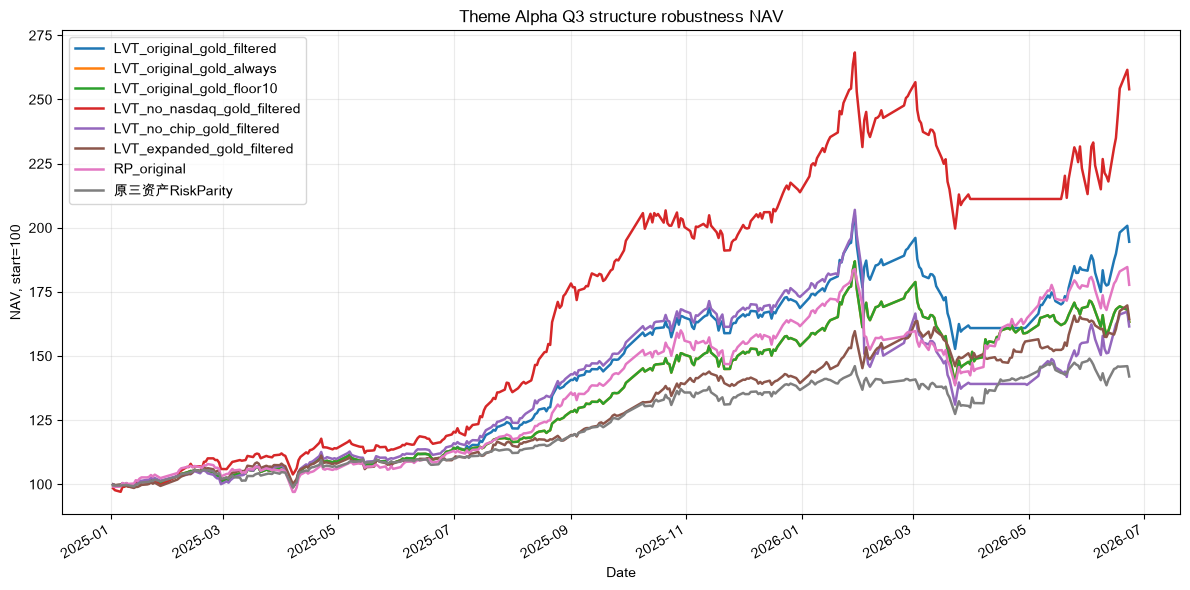

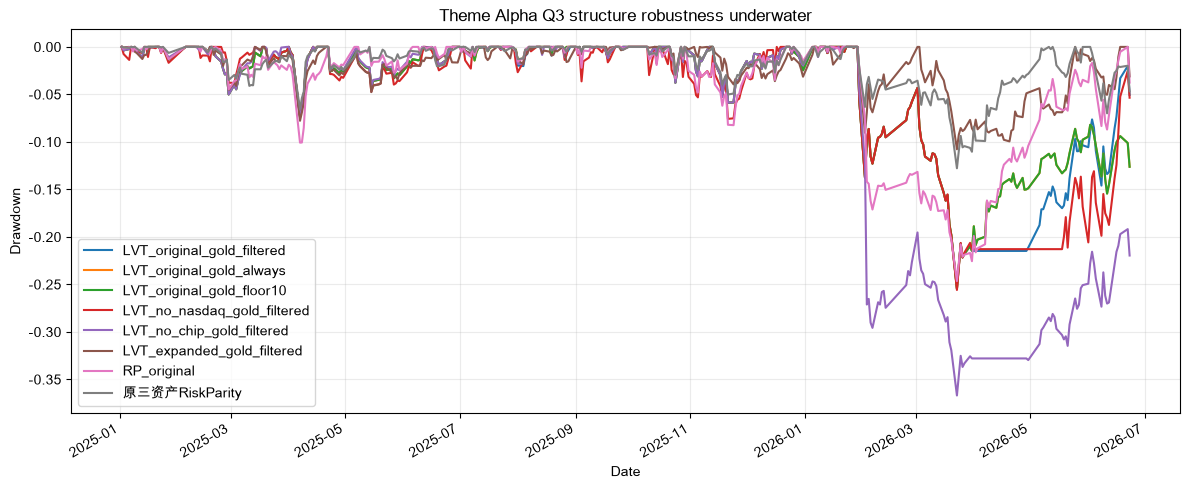

,best_return_2025_to_date,best_sharpe_2025_to_date,best_calmar_2025_to_date,best_return_2026_ytd,gold_filtered_return,gold_always_return,gold_floor10_return,no_nasdaq_return,no_chip_return,expanded_return
0,LVT_no_nasdaq_gold_filtered,LVT_no_nasdaq_gold_filtered,LVT_expanded_gold_filtered,LVT_no_nasdaq_gold_filtered,0.9454,0.6334,0.6334,1.5399,0.6154,0.6447


In [8]:
chart_names = [
    "LVT_original_gold_filtered",
    "LVT_original_gold_always",
    "LVT_original_gold_floor10",
    "LVT_no_nasdaq_gold_filtered",
    "LVT_no_chip_gold_filtered",
    "LVT_expanded_gold_filtered",
    "RP_original",
    "原三资产RiskParity",
]
ret_df = pd.DataFrame({name: slice_returns(portfolios[name], "2025-01-01") for name in chart_names if name in portfolios})
nav_df = ret_df.apply(nav_from_returns)
underwater = nav_df.apply(lambda s: s / s.cummax() - 1.0)
nav_df.to_csv(OUTPUT_DIR / "nav_main_2025_to_date.csv", encoding="utf-8-sig")
underwater.to_csv(OUTPUT_DIR / "underwater_main_2025_to_date.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(12, 6))
nav_df.plot(ax=ax, linewidth=1.8)
ax.set_title("Theme Alpha Q3 structure robustness NAV")
ax.set_ylabel("NAV, start=100")
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "nav_structure_2025_to_date.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
underwater.plot(ax=ax, linewidth=1.5)
ax.set_title("Theme Alpha Q3 structure robustness underwater")
ax.set_ylabel("Drawdown")
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "underwater_structure_2025_to_date.png", dpi=160, bbox_inches="tight")
plt.show()

research_summary = pd.DataFrame([
    {
        "best_return_2025_to_date": summary_tables["2025_to_date"]["累计收益"].idxmax(),
        "best_sharpe_2025_to_date": summary_tables["2025_to_date"]["夏普"].idxmax(),
        "best_calmar_2025_to_date": summary_tables["2025_to_date"]["卡玛"].idxmax(),
        "best_return_2026_ytd": summary_tables["2026_ytd"]["累计收益"].idxmax(),
        "gold_filtered_return": summary_tables["2025_to_date"].loc["LVT_original_gold_filtered", "累计收益"],
        "gold_always_return": summary_tables["2025_to_date"].loc["LVT_original_gold_always", "累计收益"],
        "gold_floor10_return": summary_tables["2025_to_date"].loc["LVT_original_gold_floor10", "累计收益"],
        "no_nasdaq_return": summary_tables["2025_to_date"].loc["LVT_no_nasdaq_gold_filtered", "累计收益"],
        "no_chip_return": summary_tables["2025_to_date"].loc["LVT_no_chip_gold_filtered", "累计收益"],
        "expanded_return": summary_tables["2025_to_date"].loc["LVT_expanded_gold_filtered", "累计收益"],
    }
])
research_summary.to_csv(OUTPUT_DIR / "research_summary.csv", index=False, encoding="utf-8-sig")
display(research_summary.round(4))


## 8. Q5 Diagnostics补充

补充月度、水下、修复与结构对比表，避免只看总收益和 Sharpe。


In [9]:
# Q5-style monthly, underwater, and recovery diagnostics requested for structure review.

def monthly_diagnostics(name, r):
    m = r.dropna().resample("ME").apply(lambda x: (1.0 + x).prod() - 1.0).dropna()
    wins = m[m > 0]
    losses = m[m < 0]
    return {
        "策略": name,
        "月数": len(m),
        "月胜率": (m > 0).mean() if len(m) else np.nan,
        "平均盈利月": wins.mean() if len(wins) else np.nan,
        "平均亏损月": losses.mean() if len(losses) else np.nan,
        "最差月": m.min() if len(m) else np.nan,
        "最好月": m.max() if len(m) else np.nan,
        "盈利因子": wins.sum() / abs(losses.sum()) if len(losses) and losses.sum() != 0 else np.nan,
    }


def drawdown_events(nav):
    dd = nav / nav.cummax() - 1.0
    events = []
    in_dd = False
    start = trough = peak = None
    trough_depth = 0.0
    for date, depth in dd.items():
        if depth < 0 and not in_dd:
            in_dd = True
            start = date
            peak = nav.loc[:date].idxmax()
            trough = date
            trough_depth = depth
        elif depth < 0 and in_dd:
            if depth < trough_depth:
                trough = date
                trough_depth = depth
        elif depth >= 0 and in_dd:
            events.append({"peak_date": peak, "start_date": start, "trough_date": trough, "recovery_date": date, "depth": trough_depth, "days_to_trough": (trough - start).days, "recovery_days": (date - start).days, "recovered": True})
            in_dd = False
    if in_dd:
        last_date = dd.index[-1]
        events.append({"peak_date": peak, "start_date": start, "trough_date": trough, "recovery_date": pd.NaT, "depth": trough_depth, "days_to_trough": (trough - start).days, "recovery_days": np.nan, "unrecovered_days": (last_date - start).days, "recovered": False})
    return pd.DataFrame(events)


def underwater_recovery_diagnostics(name, r):
    nav = nav_from_returns(r.dropna())
    dd = nav / nav.cummax() - 1.0
    events = drawdown_events(nav)
    recovered = events[events["recovered"]] if len(events) else pd.DataFrame()
    unresolved = events[~events["recovered"]] if len(events) else pd.DataFrame()
    return {
        "策略": name,
        "水下时间占比": (dd < 0).mean() if len(dd) else np.nan,
        "平均水下": dd[dd < 0].mean() if (dd < 0).any() else 0.0,
        "最长水下天数": events["recovery_days"].fillna(events.get("unrecovered_days", np.nan)).max() if len(events) else 0,
        "超过-10%天数": int((dd <= -0.10).sum()),
        "平均修复天数": recovered["recovery_days"].mean() if len(recovered) else np.nan,
        "最长修复天数": recovered["recovery_days"].max() if len(recovered) else np.nan,
        "未修复回撤": unresolved["depth"].iloc[-1] if len(unresolved) else 0.0,
        "未修复天数": unresolved["unrecovered_days"].iloc[-1] if len(unresolved) and "unrecovered_days" in unresolved else 0,
        "回撤事件数": len(events),
    }


def write_diagnostics(port_map, names, window_name, start, end=None, prefix=""):
    monthly_rows = []
    underwater_rows = []
    comparison_rows = []
    for name in names:
        port = port_map[name]
        r = slice_returns(port, start, end)
        if len(r) < 20:
            continue
        monthly_rows.append(monthly_diagnostics(name, r))
        underwater_rows.append(underwater_recovery_diagnostics(name, r))
        comparison_rows.append(metrics_row(name, r, port["weights"], port["turnover"]))
    monthly_df = pd.DataFrame(monthly_rows).set_index("策略")
    underwater_df = pd.DataFrame(underwater_rows).set_index("策略")
    comparison_df = pd.DataFrame(comparison_rows).set_index("策略")
    stem = f"{prefix}_{window_name}" if prefix else window_name
    monthly_df.to_csv(OUTPUT_DIR / f"monthly_diagnostics_{stem}.csv", encoding="utf-8-sig")
    underwater_df.to_csv(OUTPUT_DIR / f"underwater_recovery_{stem}.csv", encoding="utf-8-sig")
    comparison_df.to_csv(OUTPUT_DIR / f"comparison_{stem}.csv", encoding="utf-8-sig")
    return monthly_df, underwater_df, comparison_df

q3_structure_names = [
    "RP_original",
    "LVT_original_gold_filtered",
    "LVT_original_gold_always",
    "LVT_no_nasdaq_gold_filtered",
    "LVT_no_chip_gold_filtered",
    "LVT_expanded_gold_filtered",
    "RP_expanded",
    "原三资产RiskParity",
]
q3_structure_ports = {name: portfolios[name] for name in q3_structure_names}

for window_name, (start, end) in WINDOWS.items():
    mdf, udf, cdf = write_diagnostics(q3_structure_ports, q3_structure_names, window_name, start, end, prefix="structure")
    print()
    print(f"Q3 diagnostics - {window_name}")
    display(cdf[["累计收益", "最大回撤", "夏普", "卡玛"]].round(4))
    display(mdf.round(4))
    display(udf.round(4))



Q3 diagnostics - 2025_only


,累计收益,最大回撤,夏普,卡玛
策略,,,,
RP_original,0.6163,-0.1008,3.5185,6.4036
LVT_original_gold_filtered,0.6870,-0.0731,4.1569,9.8507
LVT_original_gold_always,0.5390,-0.0731,3.3966,7.7132
LVT_no_nasdaq_gold_filtered,1.1384,-0.0757,5.4590,15.8365
LVT_no_chip_gold_filtered,0.7303,-0.0744,4.4106,10.2996
LVT_expanded_gold_filtered,0.3944,-0.0778,2.7787,5.2914
RP_expanded,0.3110,-0.0931,2.2711,3.4817
原三资产RiskParity,0.3676,-0.0658,2.8877,5.8261


,月数,月胜率,平均盈利月,平均亏损月,最差月,最好月,盈利因子
策略,,,,,,,
RP_original,12,0.9167,0.0469,-0.0162,-0.0162,0.1226,31.7412
LVT_original_gold_filtered,12,0.8333,0.0552,-0.0036,-0.0041,0.1247,77.1530
LVT_original_gold_always,12,0.8333,0.0452,-0.0036,-0.0041,0.1010,63.2593
LVT_no_nasdaq_gold_filtered,12,0.7500,0.0931,-0.0073,-0.0155,0.2692,38.0754
LVT_no_chip_gold_filtered,12,0.8333,0.0588,-0.0083,-0.0134,0.1218,35.6101
LVT_expanded_gold_filtered,12,0.8333,0.0351,-0.0037,-0.0062,0.0906,47.4050
RP_expanded,12,0.7500,0.0359,-0.0148,-0.0235,0.0773,7.2767
原三资产RiskParity,12,0.9167,0.0300,-0.0089,-0.0089,0.0852,36.9664


,水下时间占比,平均水下,最长水下天数,超过-10%天数,平均修复天数,最长修复天数,未修复回撤,未修复天数,回撤事件数
策略,,,,,,,,,
RP_original,0.6790,-0.0192,57.0,2,7.6562,57.0,-0.0151,2.0,33
LVT_original_gold_filtered,0.6749,-0.0161,50.0,0,7.2727,50.0,-0.0246,6.0,34
LVT_original_gold_always,0.6790,-0.0158,50.0,0,7.6562,50.0,-0.0246,6.0,33
LVT_no_nasdaq_gold_filtered,0.6996,-0.0195,56.0,0,7.7500,56.0,-0.0172,2.0,33
LVT_no_chip_gold_filtered,0.6502,-0.0156,38.0,0,6.1579,38.0,-0.0195,2.0,39
LVT_expanded_gold_filtered,0.7572,-0.0160,78.0,0,9.1154,78.0,-0.0395,47.0,27
RP_expanded,0.7449,-0.0171,56.0,0,7.5333,56.0,-0.0547,47.0,31
原三资产RiskParity,0.6749,-0.0136,55.0,0,9.3846,55.0,-0.0181,2.0,27



Q3 diagnostics - 2026_ytd


...

,水下时间占比,平均水下,最长水下天数,超过-10%天数,平均修复天数,最长修复天数,未修复回撤,未修复天数,回撤事件数
策略,,,,,,,,,
RP_original,0.8559,-0.1126,143.0,56,36.75,143.0,-0.0375,0.0,5
LVT_original_gold_filtered,0.8559,-0.1405,144.0,66,1.00,1.0,-0.2545,144.0,4
LVT_original_gold_always,0.8559,-0.1265,144.0,68,1.00,1.0,-0.2545,144.0,4
LVT_no_nasdaq_gold_filtered,0.8559,-0.1569,144.0,73,1.00,1.0,-0.2558,144.0,4
LVT_no_chip_gold_filtered,0.8739,-0.2645,144.0,91,1.75,3.0,-0.3669,144.0,5
LVT_expanded_gold_filtered,0.8378,-0.0504,82.0,1,24.00,82.0,-0.0311,0.0,7
RP_expanded,0.9279,-0.0917,144.0,43,3.75,11.0,-0.1732,144.0,5
原三资产RiskParity,0.8649,-0.0421,101.0,6,22.00,101.0,-0.0699,20.0,7



Q3 diagnostics - 2025_to_date


,累计收益,最大回撤,夏普,卡玛
策略,,,,
RP_original,0.7776,-0.2465,2.2452,2.0532
LVT_original_gold_filtered,0.9454,-0.2545,2.5549,2.3814
LVT_original_gold_always,0.6334,-0.2545,1.8197,1.6429
LVT_no_nasdaq_gold_filtered,1.5399,-0.2558,3.3387,3.6810
LVT_no_chip_gold_filtered,0.6154,-0.3669,1.4709,1.1092
LVT_expanded_gold_filtered,0.6447,-0.1077,2.3098,3.9447
RP_expanded,0.2720,-0.1732,1.1838,1.0784
原三资产RiskParity,0.4204,-0.1277,1.7673,2.2217


,月数,月胜率,平均盈利月,平均亏损月,最差月,最好月,盈利因子
策略,,,,,,,
RP_original,18,0.8333,0.0575,-0.0786,-0.1144,0.1567,3.6609
LVT_original_gold_filtered,18,0.7778,0.0641,-0.0437,-0.1666,0.1456,5.1362
LVT_original_gold_always,18,0.7222,0.0571,-0.0413,-0.1666,0.1456,3.5963
LVT_no_nasdaq_gold_filtered,18,0.6667,0.1014,-0.0375,-0.1647,0.2692,6.4838
LVT_no_chip_gold_filtered,18,0.7222,0.0683,-0.0677,-0.1886,0.1404,2.6205
LVT_expanded_gold_filtered,18,0.7778,0.0413,-0.0150,-0.0521,0.1172,9.6631
RP_expanded,18,0.6667,0.0395,-0.0358,-0.0779,0.0876,2.2116
原三资产RiskParity,18,0.7778,0.0360,-0.0340,-0.0749,0.0922,3.7051


,水下时间占比,平均水下,最长水下天数,超过-10%天数,平均修复天数,最长修复天数,未修复回撤,未修复天数,回撤事件数
策略,,,,,,,,,
RP_original,0.7345,-0.0533,143.0,58,10.7838,143.0,-0.0375,0.0,38
LVT_original_gold_filtered,0.7345,-0.0615,144.0,66,6.8919,50.0,-0.2545,144.0,38
LVT_original_gold_always,0.7373,-0.0560,144.0,68,7.2222,50.0,-0.2545,144.0,37
LVT_no_nasdaq_gold_filtered,0.7486,-0.0688,144.0,73,7.1667,56.0,-0.2558,144.0,37
LVT_no_chip_gold_filtered,0.7232,-0.1099,144.0,91,5.7907,38.0,-0.3669,144.0,44
LVT_expanded_gold_filtered,0.7881,-0.0274,82.0,1,13.1818,82.0,-0.0311,0.0,34
RP_expanded,0.8051,-0.0440,144.0,43,8.4000,56.0,-0.1732,144.0,36
原三资产RiskParity,0.7373,-0.0240,101.0,6,11.6364,101.0,-0.0699,20.0,34
